Esse trabalaho se trata de Consolidação do Conteúdo da disciplina de Reconhecimento de Padrões do mestrado em computação aplicada do IFES.  
Aluno/Autor: Júlio Moraes Silva Scopel

## INTRODUÇÃO
Desafio escolhido: Predicting Airline Satisfaction — Kaggle Playground Series S6E10 (https://www.kaggle.com/competitions/playground-series-s6e10)

O objetivo do desafio é desenvolver e avaliar modelos de aprendizado de máquina capazes de prever a satisfação de passageiros de companhias aéreas com base em características relacionadas à sua viagem e à experiência de serviço.
O problema é caracterizado como uma tarefa de classificação binária supervisionada, na qual o target "satisfaction" representa a satisfação do passageiro. A métrica principal de avaliação será a área sob a curva ROC (ROC-AUC), conforme definido no desafio.

## 1. Bibliotecas e configuração

In [3]:
from pathlib import Path
#import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score, recall_score,
    f1_score, classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 42 #A semente aleatória é definida para tornar as divisões e os modelos tão reprodutíveis quanto possível.
TEST_SIZE = 0.20

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

## 2. Carregamento dos arquivos

In [4]:
DATA_DIR = Path(".")

train_path = DATA_DIR / "train.csv"
test_path = DATA_DIR / "test.csv"

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path) if test_path.exists() else None

TARGET = "satisfaction"

print(f"Treinamento: {train_df.shape[0]:,} linhas × {train_df.shape[1]:,} colunas")
if test_df is not None:
    print(f"Teste: {test_df.shape[0]:,} linhas × {test_df.shape[1]:,} colunas")
print(f"Target: {TARGET}")

Treinamento: 699,635 linhas × 23 colunas
Teste: 299,844 linhas × 22 colunas
Target: satisfaction


## 3. Compreensão inicial do dataset

Nessa etapa é possível identificar quantidade de linhas e colunas, observar algumas linhas, os nomes das colunas, os tipos de dados, se existem valores faltantes e quantidades.É possível distinguir variáveis numéricas, categóricas e identificadora (Coluna Id).

In [18]:
display(train_df.info())

<class 'pandas.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11  On-board service                   699635 non-null

None

In [17]:
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
display(train_df.head())
display(pd.DataFrame({
    "tipo": train_df.dtypes.astype(str),
    "valores_unicos": train_df.nunique(dropna=False),
    "faltantes": train_df.isna().sum(),
    "faltantes_%": (train_df.isna().mean() * 100).round(2)
}).sort_values("faltantes_%", ascending=False))

display(train_df.describe(include="all").T)

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


,tipo,valores_unicos,faltantes,faltantes_%
Arrival Delay in Minutes,float64,169,292,0.04
Age,int64,75,0,0.00
id,int64,699635,0,0.00
Inflight wifi service,int64,6,0,0.00
Departure/Arrival time convenient,int64,6,0,0.00
Ease of Online booking,int64,6,0,0.00
Flight Distance,int64,3474,0,0.00
Gate location,int64,6,0,0.00
Food and drink,int64,6,0,0.00
Seat comfort,int64,6,0,0.00


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,699635.0,NaN,NaN,NaN,349817.0,201967.37213,0.0,174908.5,349817.0,524725.5,699634.0
Age,699635.0,NaN,NaN,NaN,39.001928,13.800943,7.0,27.0,40.0,50.0,85.0
Flight Distance,699635.0,NaN,NaN,NaN,1353.778702,954.422566,67.0,631.0,954.0,1814.0,4983.0
Inflight wifi service,699635.0,NaN,NaN,NaN,2.778722,1.280419,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,699635.0,NaN,NaN,NaN,3.15621,1.47539,0.0,2.0,3.0,4.0,5.0
Ease of Online booking,699635.0,NaN,NaN,NaN,2.81324,1.32955,0.0,2.0,3.0,4.0,5.0
Gate location,699635.0,NaN,NaN,NaN,3.013734,1.254014,0.0,2.0,3.0,4.0,5.0
Food and drink,699635.0,NaN,NaN,NaN,3.265644,1.300202,0.0,2.0,3.0,4.0,5.0
Online boarding,699635.0,NaN,NaN,NaN,3.364156,1.288538,0.0,2.0,4.0,4.0,5.0
Seat comfort,699635.0,NaN,NaN,NaN,3.56895,1.275333,0.0,3.0,4.0,5.0,5.0


## 4. Análise exploratória dos dados (EDA)

A análise exploratória busca compreender a distribuição do TARGET, a distribuição das variáveis numéricas e a relação inicial entre atributos e satisfação.

In [19]:
print("Distribuição da variável-alvo:")
display(train_df[TARGET].value_counts(dropna=False).to_frame("quantidade"))
display((train_df[TARGET].value_counts(normalize=True, dropna=False) * 100)
        .round(2).to_frame("percentual"))

id_like_cols = ['id']

print("Coluna identificadora:", id_like_cols)

Distribuição da variável-alvo:


,quantidade
satisfaction,
False,389296
True,310339


,percentual
satisfaction,
False,55.64
True,44.36


Coluna identificadora: ['id']


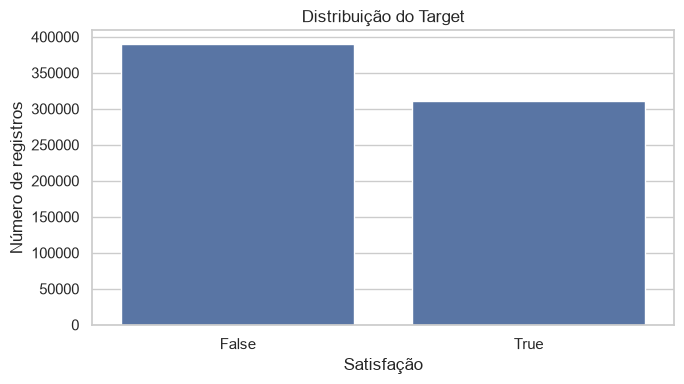

In [6]:
# Distribuição da variável-alvo
plt.figure(figsize=(7, 4))
ax = sns.countplot(data=train_df, x=TARGET)
ax.set_title("Distribuição do Target")
ax.set_xlabel("Satisfação")
ax.set_ylabel("Número de registros")
plt.tight_layout()
plt.show()

In [20]:
# Separação das colunas numéricas e categóricas
feature_cols_eda = [c for c in train_df.columns if c != TARGET and c not in id_like_cols]
numeric_cols_eda = train_df[feature_cols_eda].select_dtypes(include=np.number).columns.tolist()
categorical_cols_eda = [c for c in feature_cols_eda if c not in numeric_cols_eda]

print(f"Variáveis numéricas ({len(numeric_cols_eda)}):", numeric_cols_eda)
print(f"Variáveis categóricas ({len(categorical_cols_eda)}):", categorical_cols_eda)

Variáveis numéricas (17): ['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']
Variáveis categóricas (4): ['Gender', 'Customer Type', 'Type of Travel', 'Class']


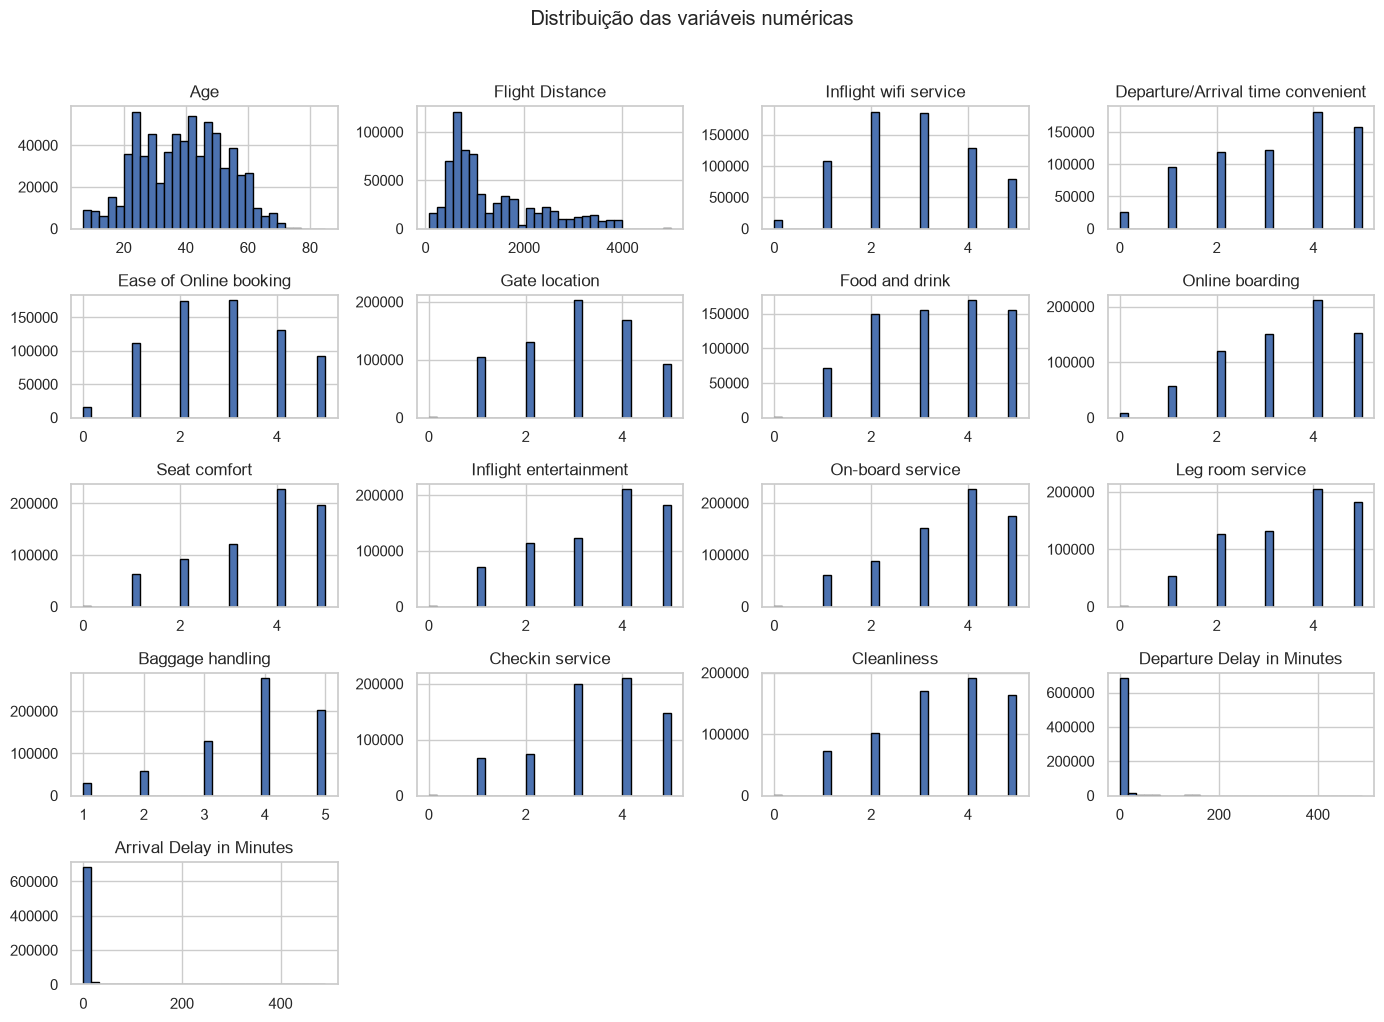

In [26]:
# Histogramas das variáveis numéricas
train_df[numeric_cols_eda].hist(figsize=(14, 10), bins=30, edgecolor="black")
plt.suptitle("Distribuição das variáveis numéricas", y=1.02)
plt.tight_layout()
plt.show()

## 4.1 Análise da distribuição das variáveis numéricas

A análise da distribuição das variáveis numéricas foi realizada por meio de histogramas, permitindo observar a frequência dos valores e identificar características relevantes do conjunto de dados.

A variável Age apresenta maior concentração de passageiros em faixas etárias intermediárias, enquanto Flight Distance demonstra uma distribuição assimétrica à direita, indicando maior frequência de voos com distâncias menores e menor ocorrência de voos mais longos.

As variáveis relacionadas às avaliações dos serviços oferecidos pelas companhias aéreas apresentam distribuições discretas, com concentrações em diferentes níveis da escala de avaliação. Destacam-se as variáveis Seat comfort, Online boarding e Cleanliness, que apresentam maior frequência de avaliações nos níveis superiores. Por outro lado, atributos como Inflight wifi service e Ease of Online booking apresentam distribuições mais dispersas.

Em relação às variáveis de atraso, Departure Delay in Minutes e Arrival Delay in Minutes apresentam distribuições fortemente assimétricas à direita, caracterizadas pela concentração de observações próximas de zero e pela ocorrência de uma quantidade menor de atrasos elevados. Esse comportamento evidencia a presença de valores extremos, que devem ser considerados durante a preparação dos dados.

De maneira geral, a análise permitiu identificar diferentes padrões de distribuição entre os atributos, contribuindo para a compreensão das características do conjunto de dados e orientando as etapas posteriores de preparação e modelagem.

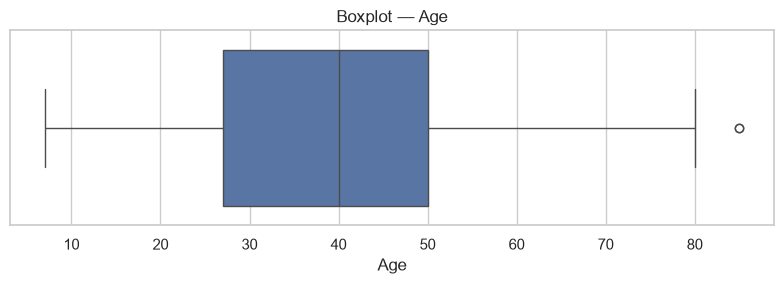

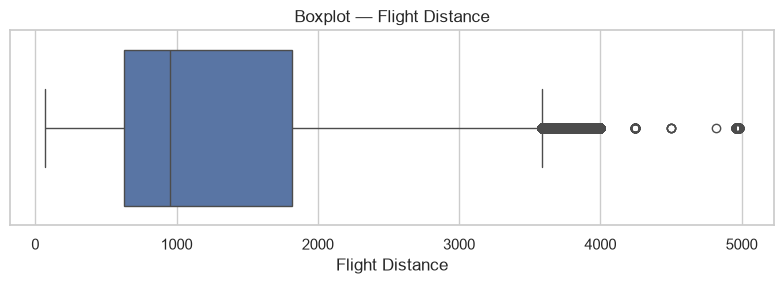

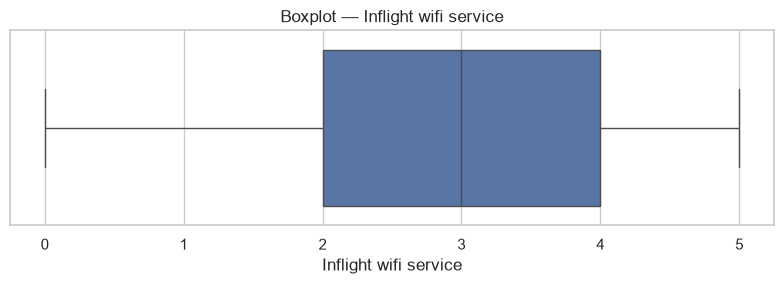

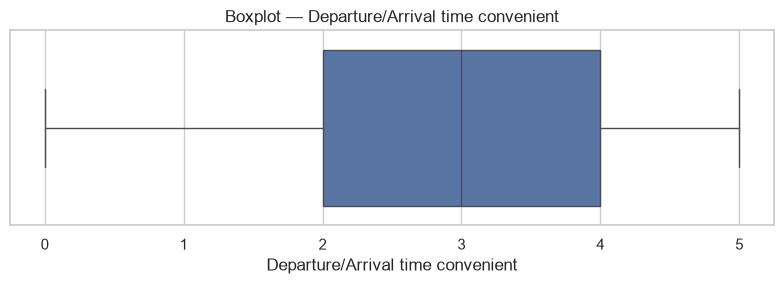

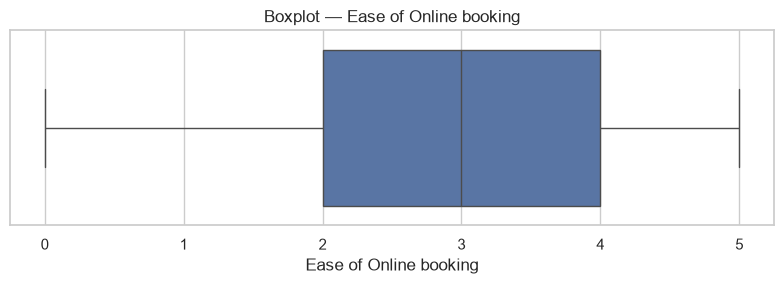

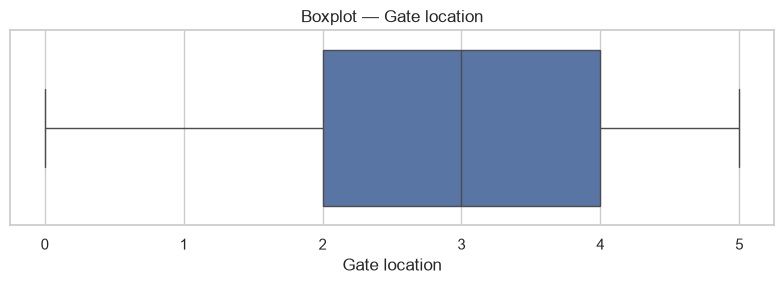

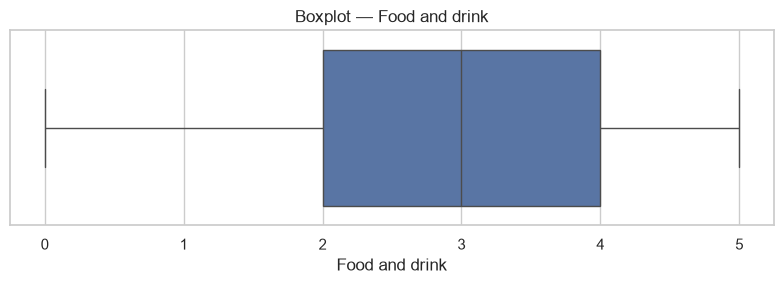

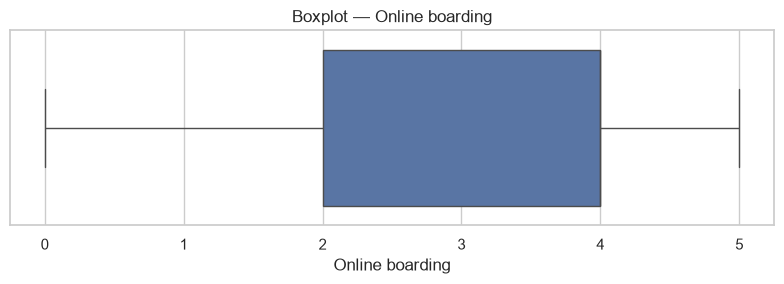

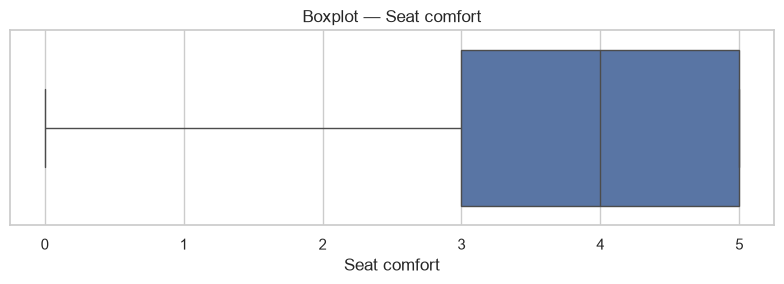

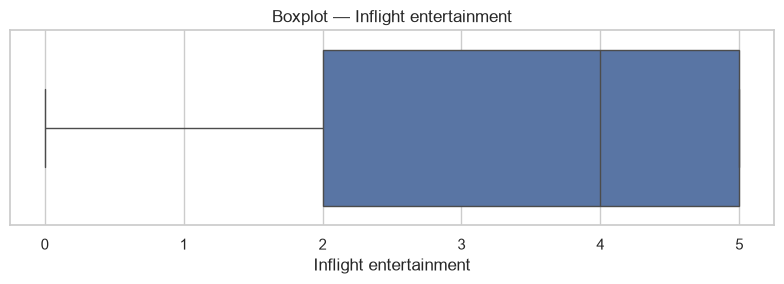

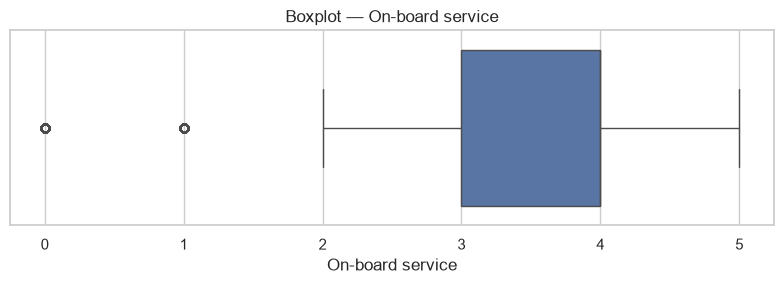

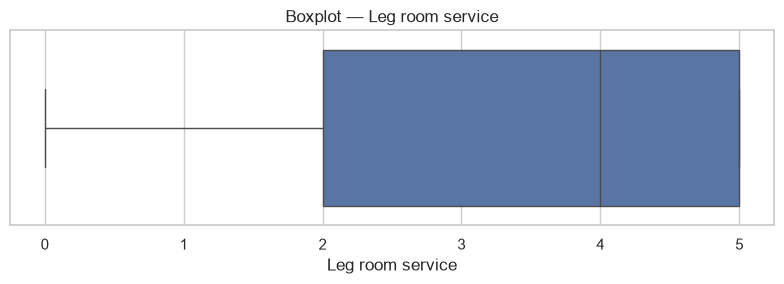

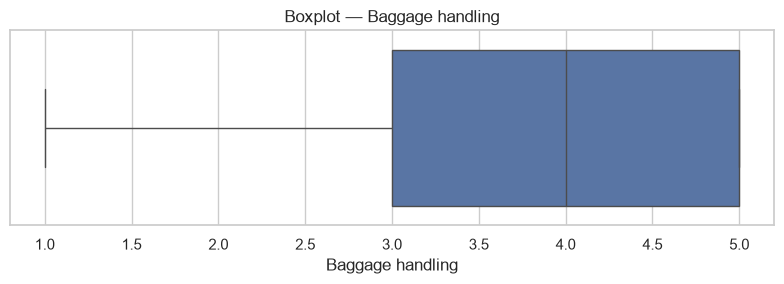

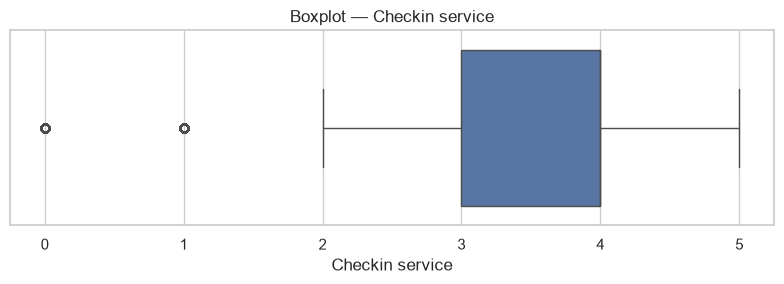

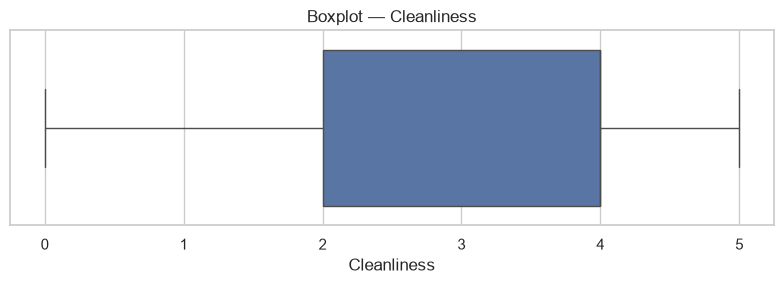

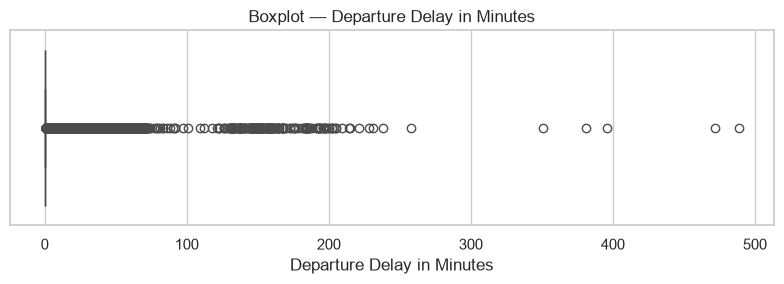

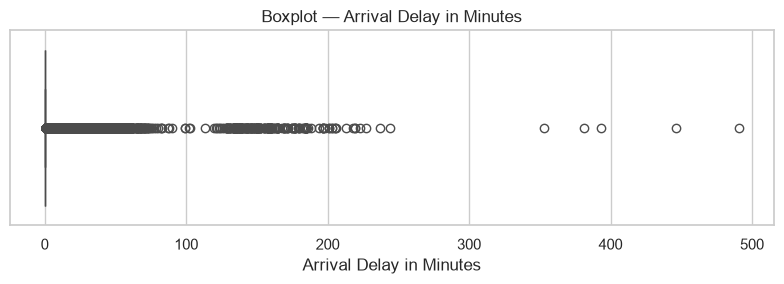

In [46]:
# Plotar Boxplots que ajudam a identificar dispersão e possíveis valores extremos.
for col in numeric_cols_eda:
    plt.figure(figsize=(8, 3))
    sns.boxplot(data=train_df, x=col)
    plt.title(f"Boxplot — {col}")
    plt.tight_layout()
    plt.show()

## 4.2 Análise dos boxplots

A análise dos boxplots foi realizada com o objetivo de investigar a dispersão das variáveis numéricas, identificar suas medidas de tendência central e verificar a presença de possíveis valores extremos (outliers).

Entre as variáveis relacionadas ao perfil dos passageiros e às características da viagem, Age apresenta mediana próxima de 40 anos, com um valor extremo na faixa etária mais elevada. Já Flight Distance demonstra maior dispersão e apresenta diversos valores extremos, principalmente em distâncias superiores a aproximadamente 3.600 km, indicando a ocorrência de uma quantidade menor de voos significativamente mais longos.

Nas variáveis relacionadas às avaliações dos serviços, observa-se que as medianas estão predominantemente entre 3 e 4, sugerindo concentração das avaliações em níveis intermediários e superiores. Foram identificados valores extremos nas variáveis On-board service e Checkin service, associados às avaliações 0 e 1. Porém, por se tratarem de valores pertencentes à escala original de avaliação, não foram considerados como registros inválidos.

De maneira geral, a análise permitiu identificar diferenças relevantes na dispersão das variáveis e possíveis valores extremos. Entretanto, optou-se por não realizar a exclusão automática dessas observações, uma vez que os valores identificados podem representar ocorrências legítimas do contexto analisado e conter informações relevantes para a capacidade preditiva dos modelos.

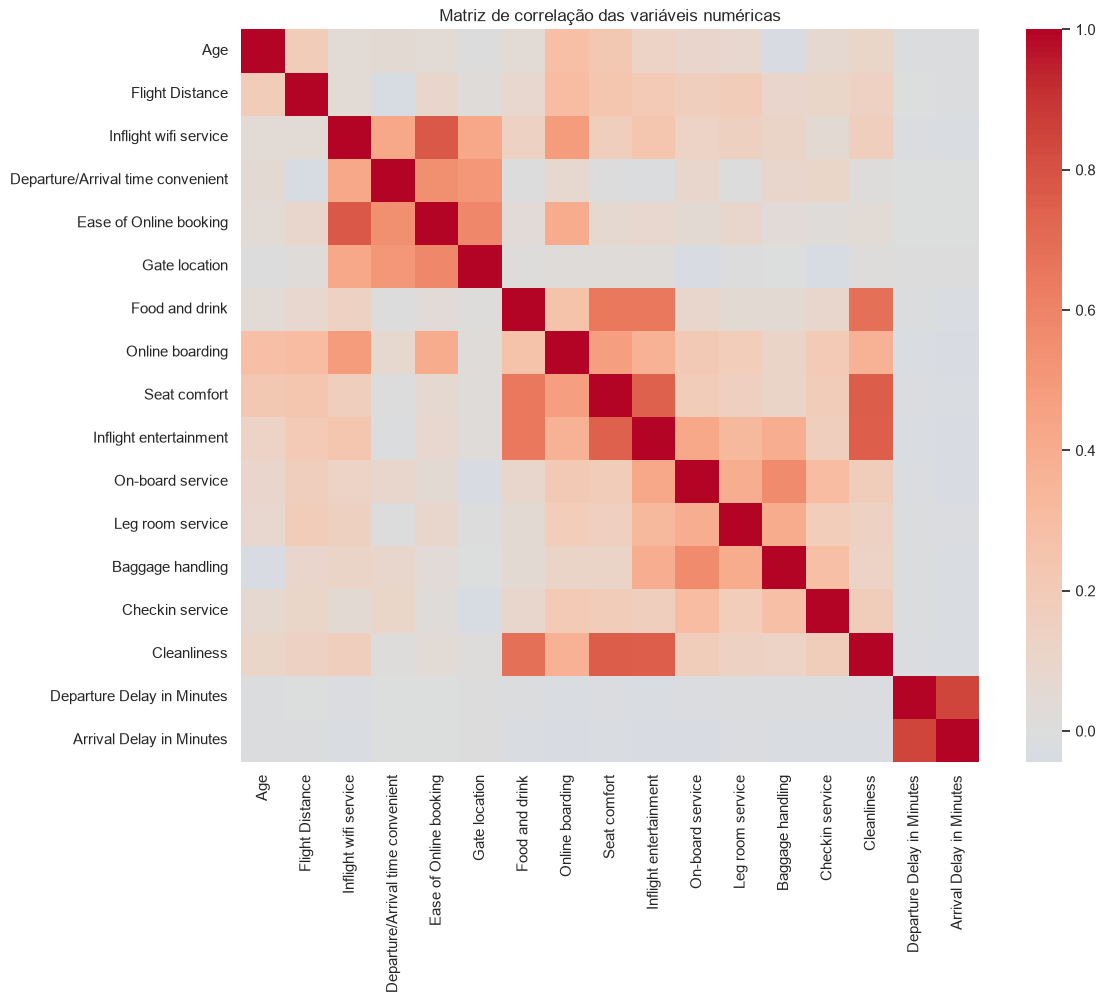

In [22]:
# Correlação de Pearson entre variáveis numéricas.
corr = train_df[numeric_cols_eda].corr(numeric_only=True)
plt.figure(figsize=(max(9, len(corr) * 0.7), max(7, len(corr) * 0.6)))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Matriz de correlação das variáveis numéricas")
plt.tight_layout()
plt.show()

## 4.3 Análise da matriz de correlação

A matriz de correlação é utilizada para investigar as relações lineares entre as variáveis numéricas do conjunto de dados, permitindo identificar possíveis associações entre os atributos utilizados na modelagem.

Entre os resultados observados, destaca-se a correlação positiva elevada entre as variáveis Departure Delay in Minutes e Arrival Delay in Minutes, indicando que atrasos na partida tendem a estar associados a atrasos na chegada dos voos.

Também foram identificadas correlações positivas entre atributos relacionados à experiência durante o voo, especialmente Seat comfort, Inflight entertainment, Cleanliness e Food and drink. Esse comportamento sugere que as avaliações dos diferentes serviços oferecidos a bordo apresentam certa associação. De maneira semelhante, as variáveis Inflight wifi service, Ease of Online booking e Online boarding demonstraram relações positivas, indicando associação entre as avaliações dos serviços digitais e de embarque.

Por outro lado, diversas combinações de variáveis apresentaram coeficientes de correlação próximos de zero, indicando baixa associação linear entre esses atributos.

De maneira geral, a análise permitiu identificar grupos de variáveis com comportamentos correlacionados, além de fornecer informações relevantes para a compreensão dos dados antes da aplicação dos algoritmos de aprendizado de máquina. Entretanto, não foi realizada a exclusão automática de variáveis com base exclusivamente na correlação, uma vez que atributos correlacionados ainda podem fornecer informações úteis para a capacidade preditiva dos modelos.

Valores observados no alvo: [False  True]
Classe tratada como positiva para as taxas exploratórias: True


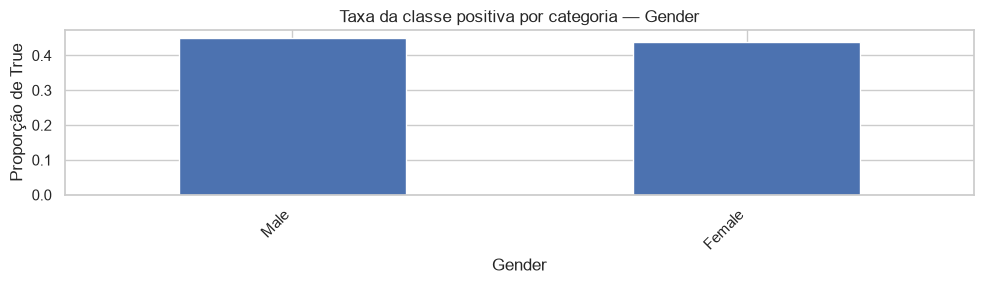

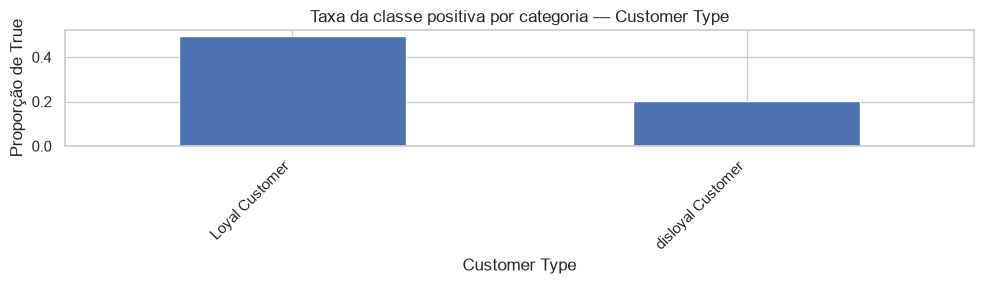

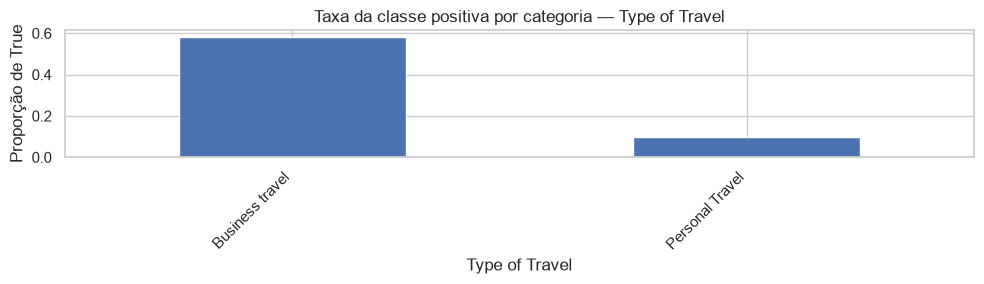

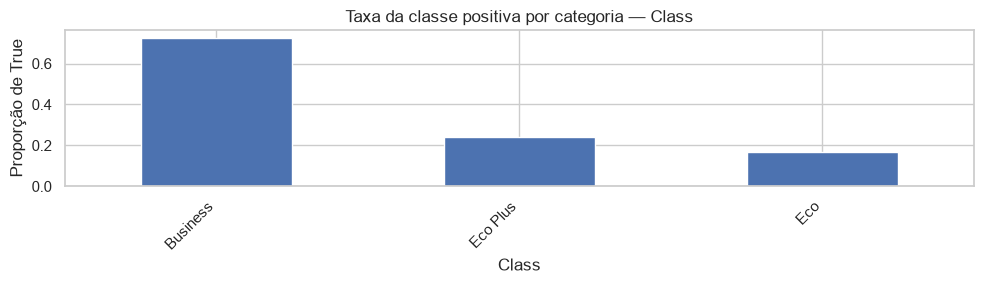

In [23]:
# Taxa da classe positiva por categoria para as primeiras variáveis categóricas.
# A conversão para 0/1 é usada apenas para resumir a taxa; o alvo original é preservado.
target_values = train_df[TARGET].dropna().unique()
print("Valores observados no alvo:", target_values)

# Define a classe positiva como a segunda classe em ordem alfabética quando há
# duas classes; confirme essa escolha no contexto da competição.
target_classes = sorted(train_df[TARGET].dropna().astype(str).unique().tolist())
if len(target_classes) == 2:
    positive_label = target_classes[1]
    print("Classe tratada como positiva para as taxas exploratórias:", positive_label)
    eda_df = train_df.copy()
    eda_df["_target_positive"] = (eda_df[TARGET].astype(str) == positive_label).astype(int)
    for col in categorical_cols_eda[:6]:
        rate = eda_df.groupby(col, dropna=False)["_target_positive"].mean().sort_values(ascending=False)
        plt.figure(figsize=(10, max(3, min(7, len(rate) * 0.35))))
        rate.plot(kind="bar")
        plt.title(f"Taxa da classe positiva por categoria — {col}")
        plt.ylabel(f"Proporção de {positive_label}")
        plt.xlabel(col)
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()
else:
    print("O alvo não possui exatamente duas classes; adapte esta análise.")

### 4.4 Análise da taxa de satisfação por categoria
Com o objetivo de investigar a relação entre as variáveis categóricas e a satisfação dos passageiros, foi calculada a proporção da classe positiva para cada categoria dos atributos analisados.

Os resultados demonstraram diferenças expressivas entre algumas categorias. Na variável Customer Type, passageiros classificados como clientes fiéis apresentaram uma taxa de satisfação próxima de 49%, enquanto os clientes não fiéis registraram aproximadamente 20%.

A variável Type of Travel apresentou a maior diferença entre suas categorias. Passageiros que viajavam a negócios apresentaram uma taxa de satisfação próxima de 57%, enquanto aqueles que viajavam por motivos pessoais registraram aproximadamente 9%.

Também foram observadas diferenças relevantes na variável Class. A categoria Business apresentou uma proporção de passageiros satisfeitos próxima de 73%, enquanto as categorias Eco Plus e Eco registraram aproximadamente 24% e 17%, respectivamente.

Já para a variável Gender, as taxas de satisfação foram relativamente próximas entre os grupos masculino e feminino, indicando uma diferença pouco significativa.

## 5. Preparação dos dados

O Target é separado dos atributos. A coluna-alvo não deve ser incluída nas entradas do modelo. A coluna de Identificadores (Id) é removida dos preditores por não possuir relevância. 

In [28]:
X = train_df.drop(columns=[TARGET] + id_like_cols, errors="ignore").copy()
y = train_df[TARGET].copy()

# Remover do conjunto de teste as mesmas colunas identificadoras presentes no treino.
if test_df is not None:
    X_competition_test = test_df.drop(columns=id_like_cols, errors="ignore").copy()
    # Alinha as colunas do teste àquelas usadas no treinamento.
    X_competition_test = X_competition_test.reindex(columns=X.columns)

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

print("Número de atributos:", X.shape[1])
print("Numéricos:", len(numeric_features))
print("Categóricos:", len(categorical_features))
print("Faltantes em X:", int(X.isna().sum().sum()))

Número de atributos: 21
Numéricos: 17
Categóricos: 4
Faltantes em X: 292


## 5.1 Dados faltantes e tratamento

Durante a análise da qualidade dos dados, foram identificados 292 valores ausentes na variável "ArrivalDelayinMinutes", que representa o atraso de chegada dos voos em minutos.

Considerando que se trata de uma variável numérica, optou-se pela estratégia de imputação pela mediana. Essa abordagem permite preservar os registros que apresentam informações incompletas, evitando a exclusão de observações que poderiam contribuir para o treinamento dos modelos.

A mediana foi escolhida por apresentar menor sensibilidade a valores extremos em comparação à média, característica relevante para variáveis relacionadas a tempos de atraso, que podem apresentar distribuições assimétricas.

A imputação foi implementada por meio da classe SimpleImputer, da biblioteca Scikit-learn, integrada aos pipelines de pré-processamento. Dessa forma, a mediana é calculada exclusivamente com os dados utilizados no treinamento de cada modelo ou partição da validação cruzada, evitando vazamento de informações entre os conjuntos de treinamento e validação.

## 5.2 Padronização e pré-processamento
As variáveis categóricas serão codificadas com One-Hot Encoding; as numéricas serão padronizadas para o método de Regressão Logística utilizando o StandardScaler(), pois ajuda a equilibrar a escala das variáveis numéricas e favorece a otimização.

O pré-processamento é colocado dentro de um Pipeline e ColumnTransformer (Distribui as transformações entre grupos de colunas para garantir que cada tipo de variável receba o tratamento adequado). Assim, imputação, codificação e padronização são ajustadas apenas nos dados de treinamento de cada divisão, reduzindo o risco de vazamento de dados.

In [29]:
# Compatibilidade com versões diferentes do scikit-learn:
# versões recentes usam sparse_output; versões anteriores usam sparse.
try:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
except TypeError:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse=True)

numeric_preprocessor_scaled = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

numeric_preprocessor_tree = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", one_hot)
])

preprocessor_logistic = ColumnTransformer(transformers=[
    ("num", numeric_preprocessor_scaled, numeric_features),
    ("cat", categorical_preprocessor, categorical_features)
], remainder="drop")

# Para árvores, a padronização não é necessária; a codificação e imputação são mantidas.
try:
    one_hot_tree = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
except TypeError:
    one_hot_tree = OneHotEncoder(handle_unknown="ignore", sparse=True)

categorical_preprocessor_tree = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", one_hot_tree)
])

preprocessor_tree = ColumnTransformer(transformers=[
    ("num", numeric_preprocessor_tree, numeric_features),
    ("cat", categorical_preprocessor_tree, categorical_features)
], remainder="drop")

print("Pré-processadores definidos.")

Pré-processadores definidos.


## 6. Divisão dos dados

O conjunto de treinamento disponibilizado pela competição contém os rótulos e será dividido em treino local e validação. A divisão estratificada preserva aproximadamente a proporção das classes em ambos os subconjuntos.

O arquivo `test.csv` é reservado para gerar previsões de submissão somente após a comparação dos modelos.

In [30]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Treino:", X_train.shape, "| Validação:", X_valid.shape)
print("\nProporção das classes — conjunto completo:")
display(y.value_counts(normalize=True).rename("proporção").to_frame())
print("Proporção das classes — treino:")
display(y_train.value_counts(normalize=True).rename("proporção").to_frame())
print("Proporção das classes — validação:")
display(y_valid.value_counts(normalize=True).rename("proporção").to_frame())

Treino: (559708, 21) | Validação: (139927, 21)

Proporção das classes — conjunto completo:


,proporção
satisfaction,
False,0.556427
True,0.443573


Proporção das classes — treino:


,proporção
satisfaction,
False,0.556428
True,0.443572


Proporção das classes — validação:


,proporção
satisfaction,
False,0.556426
True,0.443574


## 7. Modelagem e comparação

Para a etapa de modelagem, foram selecionados três algoritmos de classificação: Regressão Logística, Árvore de Decisão e Random Forest. A escolha buscou contemplar diferentes abordagens de aprendizado de máquina, permitindo comparar modelos lineares, modelos baseados em árvores e métodos ensemble.

A Regressão Logística foi selecionada como modelo de referência, por ser um algoritmo tradicional de classificação binária, apresentar relativa simplicidade e permitir interpretar a influência das variáveis preditoras sobre as probabilidades estimadas. Sua utilização possibilita avaliar o desempenho de uma abordagem linear no problema proposto.

A Árvore de Decisão foi escolhida por sua capacidade de representar relações não lineares e identificar interações entre atributos por meio de regras de decisão. Além disso, sua estrutura permite uma interpretação mais direta dos critérios utilizados na classificação.

Por sua vez, o Random Forest foi selecionado por utilizar uma abordagem ensemble, combinando múltiplas árvores de decisão para produzir uma classificação mais robusta. A combinação de diferentes árvores busca reduzir a variância do modelo individual e melhorar sua capacidade de generalização.

Dessa forma, a utilização dos três algoritmos possibilita uma comparação entre diferentes estratégias de aprendizado, permitindo investigar quais abordagens apresentam melhor desempenho na identificação de padrões associados à satisfação dos passageiros. A comparação utiliza ROC-AUC como métrica principal, conforme proposto pelo desafio mas posteriormente serão calculadas outras métricas de desempenho (Acurácia, Precisão, Recall e F1-Score) para o modelo selecionado.

Foi realizada validação cruzada stratified k-fold cross validation com k=5, por possuir um equilíbrio entre custo computacional e avaliação dos modelos. Além disso, a estratificação preserva aproximadamente a proporção das classes da variável-alvo em cada partição, reduzindo possíveis distorções na avaliação.

In [31]:
CV_FOLDS = 5 #Utilizado na Validação Cruzada

models = {
    "Regressão Logística": Pipeline(steps=[
        ("preprocess", preprocessor_logistic),
        ("model", LogisticRegression(max_iter=1500, random_state=RANDOM_STATE))
    ]),
    "Árvore de Decisão": Pipeline(steps=[
        ("preprocess", preprocessor_tree),
        ("model", DecisionTreeClassifier(
            max_depth=12, min_samples_leaf=10, random_state=RANDOM_STATE
        ))
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocess", preprocessor_tree),
        ("model", RandomForestClassifier(
            n_estimators=150,
            min_samples_leaf=2,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
}

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "accuracy": "accuracy"}

cv_results = []
for name, model in models.items():
    print(f"Executando validação cruzada: {name}")
    scores = cross_validate(
        model, X_train, y_train,
        cv=cv, scoring=scoring,
        n_jobs=1, return_train_score=False
    )
    cv_results.append({
        "Modelo": name,
        "ROC-AUC média": scores["test_roc_auc"].mean(),
        "ROC-AUC desvio-padrão": scores["test_roc_auc"].std(),
        "Acurácia média": scores["test_accuracy"].mean()
    })

cv_results_df = pd.DataFrame(cv_results).sort_values("ROC-AUC média", ascending=False)
display(cv_results_df.style.format({
    "ROC-AUC média": "{:.4f}",
    "ROC-AUC desvio-padrão": "{:.4f}",
    "Acurácia média": "{:.4f}"
}))

Executando validação cruzada: Regressão Logística
Executando validação cruzada: Árvore de Decisão
Executando validação cruzada: Random Forest


,Modelo,ROC-AUC média,ROC-AUC desvio-padrão,Acurácia média
2,Random Forest,0.9558,0.0006,0.9257
1,Árvore de Decisão,0.9529,0.0005,0.9196
0,Regressão Logística,0.9219,0.0007,0.8785


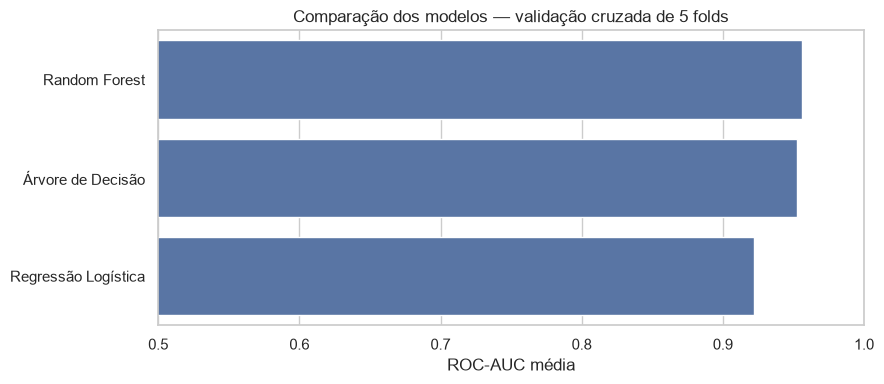

In [32]:
plt.figure(figsize=(9, 4))
sns.barplot(data=cv_results_df, x="ROC-AUC média", y="Modelo")
plt.xlim(0.5, 1.0)
plt.title(f"Comparação dos modelos — validação cruzada de {CV_FOLDS} folds")
plt.xlabel("ROC-AUC média")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 8. Avaliação no conjunto de validação

A validação cruzada auxilia a comparar os modelos mas é importante avaliar o o modelo selecionado em uma divisão de validação separada. A seleção é baseada na ROC-AUC média da validação cruzada, ou seja, é selecionado o modelo Random Forest.
Essa separação é importante para verificar se o desempenho observado na validação cruzada se mantém em dados que não foram utilizados no ajuste final do modelo.

Para o modelo selcionado é calculado outras métricas de desempenho (Acurácia, Precisão, Recall e F1-Score) de forma complementar ao ROC-AUC.

A acurácia foi utilizada para mensurar a proporção geral de classificações corretas. A precisão permite avaliar a confiabilidade das previsões positivas, enquanto o recall mede a capacidade do modelo de identificar corretamente as observações pertencentes à classe positiva. Por sua vez, o F1-score sintetiza precisão e recall em uma única medida, permitindo observar o equilíbrio entre essas duas dimensões.

A utilização conjunta dessas métricas proporciona uma avaliação mais completa dos modelos, uma vez que o desempenho de um classificador não deve ser analisado exclusivamente pelo percentual geral de acertos, mas também pela sua capacidade de distinguir e identificar corretamente as diferentes classes.

In [33]:
best_model_name = cv_results_df.iloc[0]["Modelo"]
best_model = models[best_model_name]
print("Modelo selecionado pela ROC-AUC média na validação cruzada:", best_model_name)

best_model.fit(X_train, y_train)
valid_prob = best_model.predict_proba(X_valid)[:, 1]
valid_pred = best_model.predict(X_valid)

# ROC-AUC usa os scores/probabilidades, não as classes já limiarizadas.
valid_auc = roc_auc_score(y_valid, valid_prob)
valid_accuracy = accuracy_score(y_valid, valid_pred)
valid_precision = precision_score(y_valid, valid_pred, average="binary", zero_division=0)
valid_recall = recall_score(y_valid, valid_pred, average="binary", zero_division=0)
valid_f1 = f1_score(y_valid, valid_pred, average="binary", zero_division=0)

metrics_df = pd.DataFrame([{
    "Modelo": best_model_name,
    "ROC-AUC": valid_auc,
    "Acurácia": valid_accuracy,
    "Precisão": valid_precision,
    "Recall": valid_recall,
    "F1-score": valid_f1
}])
display(metrics_df.style.format({c: "{:.4f}" for c in metrics_df.columns if c != "Modelo"}))
print(classification_report(y_valid, valid_pred, zero_division=0))

Modelo selecionado pela ROC-AUC média na validação cruzada: Random Forest


,Modelo,ROC-AUC,Acurácia,Precisão,Recall,F1-score
0,Random Forest,0.9547,0.9242,0.9261,0.9010,0.9134


              precision    recall  f1-score   support

       False       0.92      0.94      0.93     77859
        True       0.93      0.90      0.91     62068

    accuracy                           0.92    139927
   macro avg       0.92      0.92      0.92    139927
weighted avg       0.92      0.92      0.92    139927



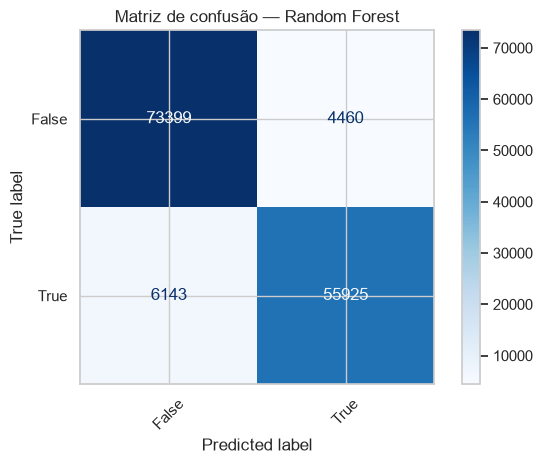

In [36]:
# Matriz de confusão com o limiar padrão de classificação.
ConfusionMatrixDisplay.from_predictions(
    y_valid, valid_pred, xticks_rotation=45, cmap="Blues", values_format="d"
)
plt.title(f"Matriz de confusão — {best_model_name}")
plt.tight_layout()
plt.show()

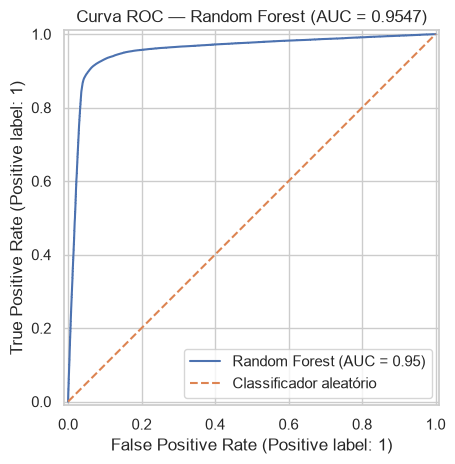

In [37]:
# Curva ROC e AUC no conjunto de validação.
RocCurveDisplay.from_predictions(y_valid, valid_prob, name=best_model_name)
plt.plot([0, 1], [0, 1], linestyle="--", label="Classificador aleatório")
plt.title(f"Curva ROC — {best_model_name} (AUC = {valid_auc:.4f})")
plt.legend()
plt.tight_layout()
plt.show()

### 8.1 Interpretação dos resultados

Os resultados indicam que o Random Forest apresentou um bom desempenho na previsão da satisfação dos passageiros, alcançando resultados consistentes nas cinco métricas avaliadas

- **ROC-AUC (0,9547):** excelente capacidade de distinguir passageiros satisfeitos e insatisfeitos. O resultado indica que o modelo consegue ordenar corretamente os exemplos das duas classes com alta capacidade discriminatória.
- **Acurácia (92,42%):** aproximadamente 92 de cada 100 passageiros foram classificados corretamente.
- **Precisão (92,61%):** entre os passageiros classificados como pertencentes à classe positiva, aproximadamente 93% realmente pertencem a essa classe.
- **Recall (90,10%):** o modelo identificou corretamente aproximadamente 90% dos passageiros que realmente pertencem à classe positiva.
- **F1-score (91,34%):** demonstra um bom equilíbrio entre precisão e recall.

O classification_report apresenta uma visão mais detalhada do desempenho para cada classe:

**Classe False (insatisfeitos):**
- Precisão de 92%: das previsões de insatisfação, 92% estavam corretas.
- Recall de 94%: o modelo identificou 94% dos passageiros realmente insatisfeitos.
- F1-score de 93%: bom equilíbrio entre precisão e recall.
  
**Classe True (satisfeitos):**
- Precisão de 93%: das previsões de satisfação, 93% estavam corretas.
- Recall de 90%: o modelo identificou 90% dos passageiros realmente satisfeitos.
- F1-score de 91%: também apresenta bom equilíbrio entre precisão e recall.
  
Um ponto interessante é que o modelo apresentou recall um pouco maior para a classe False (94%) do que para a classe True (90%). Portanto, ele teve maior facilidade para identificar passageiros insatisfeitos do que satisfeitos.

A matriz de confusão mostra que dos 139.927 registros avaliados, o modelo classificou corretamente 129.324 observações, sendo 73.399 passageiros insatisfeitos e 55.925 passageiros satisfeitos. Por outro lado, foram observadas 10.603 classificações incorretas, das quais 4.460 corresponderam a passageiros insatisfeitos classificados como satisfeitos e 6.143 a passageiros satisfeitos classificados como insatisfeitos.
Embora exista uma diferença na identificação das classes, o percentual geral de acertos de 92,42% reforça a capacidade preditiva do modelo para o problema proposto.

## 9. Importância das variáveis

Com o objetivo de interpretar o comportamento do modelo selecionado, foi realizada uma análise da importância das variáveis por meio da técnica de Permutation Importance, utilizando a ROC-AUC como métrica de referência. Essa abordagem avalia a contribuição preditiva de cada atributo a partir da redução do desempenho do modelo após o embaralhamento aleatório dos valores da respectiva variável.

Os resultados demonstraram que a variável Type of Travel apresentou a maior importância média (0,08346), destacando-se em relação às demais características utilizadas pelo modelo. Em seguida, aparecem Inflight wifi service (0,04153) e Customer Type (0,03200), indicando a relevância tanto das características relacionadas ao tipo de viagem quanto da experiência e do perfil do passageiro para as previsões realizadas.

Outras variáveis que apresentaram contribuições relevantes foram Online boarding (0,01968), Class (0,01594), Flight Distance (0,01320) e Age (0,01253). Também se observa a participação de atributos relacionados à qualidade dos serviços oferecidos durante a viagem, como Checkin service, Baggage handling, Seat comfort e On-board service.

Ressalta-se que a importância por permutação representa uma medida de contribuição preditiva dentro do modelo avaliado, não estabelecendo relações de causalidade entre as variáveis e a satisfação dos passageiros.

,Variável,Importância média,Desvio-padrão
19,Type of Travel,0.08346,0.00059
2,Inflight wifi service,0.04153,0.00018
18,Customer Type,0.03200,0.00020
7,Online boarding,0.01968,0.00017
20,Class,0.01594,0.00014
1,Flight Distance,0.01320,0.00006
0,Age,0.01253,0.00010
13,Checkin service,0.01104,0.00021
12,Baggage handling,0.01058,0.00009
8,Seat comfort,0.01026,0.00007


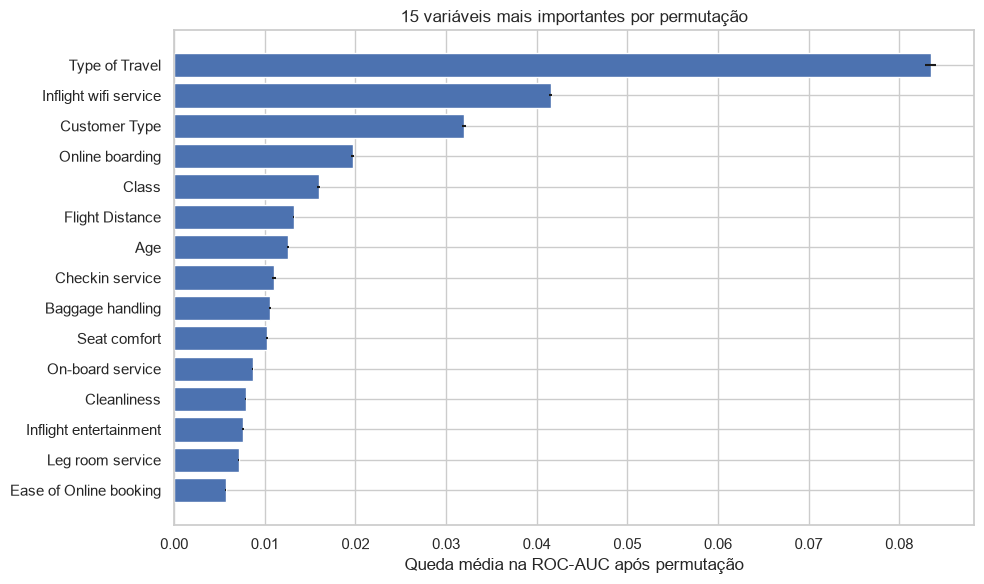

In [38]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    best_model,
    X_valid,
    y_valid,
    scoring="roc_auc",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Variável": X_valid.columns,
    "Importância média": perm.importances_mean,
    "Desvio-padrão": perm.importances_std
}).sort_values("Importância média", ascending=False)

display(importance_df.head(15).style.format({
    "Importância média": "{:.5f}",
    "Desvio-padrão": "{:.5f}"
}))

plt.figure(figsize=(10, 6))
top_imp = importance_df.head(15).sort_values("Importância média")
plt.barh(top_imp["Variável"], top_imp["Importância média"], xerr=top_imp["Desvio-padrão"])
plt.title("15 variáveis mais importantes por permutação")
plt.xlabel("Queda média na ROC-AUC após permutação")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 11. Conclusão

Este trabalho teve como objetivo desenvolver e avaliar modelos de aprendizado de máquina para prever a satisfação dos passageiros de companhias aéreas, utilizando características relacionadas ao perfil dos clientes, às condições da viagem e à experiência com os serviços oferecidos.
Inicialmente, foi realizada uma análise exploratória dos dados, seguida das etapas de preparação, tratamento de valores ausentes, codificação de variáveis categóricas e padronização das variáveis numéricas, quando necessária. Posteriormente, foram desenvolvidos e comparados três algoritmos de classificação: Regressão Logística, Árvore de Decisão e Random Forest. A comparação foi conduzida por meio de validação cruzada estratificada com cinco partições, utilizando a ROC-AUC como principal métrica de avaliação.
Entre os modelos avaliados, o Random Forest apresentou o melhor desempenho, alcançando ROC-AUC média de 0,9558 na validação cruzada. Na avaliação realizada sobre a base de validação independente, o modelo obteve ROC-AUC de 0,9547 e acurácia de 92,42%, além de precisão de 92,61%, recall de 90,10% e F1-score de 91,34%. Esses resultados demonstram uma elevada capacidade de discriminação entre passageiros satisfeitos e insatisfeitos, bem como um desempenho consistente na classificação das duas categorias.
A análise da matriz de confusão complementou essa avaliação, evidenciando que o modelo classificou corretamente 129.324 das 139.927 observações avaliadas. Também foi identificada uma capacidade ligeiramente superior de reconhecimento dos passageiros insatisfeitos, cujo recall foi de aproximadamente 94,27%, em comparação aos 90,10% observados para os passageiros satisfeitos.
Adicionalmente, a análise de importância por permutação permitiu identificar os atributos com maior contribuição para as previsões do modelo. A variável Type of Travel apresentou a maior importância média, seguida por Inflight wifi service e Customer Type. Também se destacaram características relacionadas ao embarque, à classe da viagem e à experiência durante o voo, como Online boarding, Class e Flight Distance. Esses resultados evidenciam que diferentes aspectos do perfil do passageiro e da experiência de viagem fornecem informações relevantes para a previsão da satisfação.
O Random Forest mostrou-se adequado ao problema proposto, apresentando elevado desempenho preditivo e permitindo identificar as características mais relevantes para suas decisões.
Por fim, ressalta-se que a importância das variáveis identificada neste estudo representa sua contribuição para o desempenho preditivo do modelo, não estabelecendo, por si só, relações causais com a satisfação dos passageiros.

## 11.1 Trabalhos futuros
Como possibilidades de trabalhos futuros, a sugestão é de realização de ajustes mais aprofundados dos hiperparâmetros e a avaliação de outros algoritmos de classificação. 


## 12. Reprodutibilidade

A reprodução dos experimentos deve seguir os passos descritos a seguir:

1. **Obtenção dos dados:** baixar os arquivos `train.csv` e `test.csv` disponibilizados na competição Kaggle Playground Series S6E10 (disponível em: https://www.kaggle.com/competitions/playground-series-s6e10/data).

2. **Configuração do ambiente:** utilizar Python com as bibliotecas Pandas, NumPy, Matplotlib, Seaborn e Scikit-learn instaladas. O experimento foi desenvolvido em um notebook Jupyter com as versões listadas no item 12.

3. **Organização dos arquivos:** armazenar os arquivos CSV na mesma pasta do notebook, garantindo que os nomes dos arquivos correspondam aos utilizados no código.

4. **Execução do pré-processamento:** separar a variável-alvo `satisfaction` dos atributos preditores, remover a coluna identificadora `id`, identificar variáveis numéricas e categóricas e aplicar os procedimentos de tratamento de valores ausentes, codificação categórica e padronização, conforme o algoritmo utilizado.

5. **Divisão dos dados:** realizar a separação estratificada dos dados rotulados em conjuntos de treinamento e validação, utilizando 80% para treinamento e 20% para validação.

6. **Treinamento e comparação:** executar os três algoritmos avaliados — Regressão Logística, Árvore de Decisão e Random Forest — utilizando validação cruzada estratificada com cinco partições (*Stratified 5-Fold Cross-Validation*). A seleção do melhor modelo deve considerar a ROC-AUC média obtida nas cinco partições.

7. **Avaliação:** treinar novamente o modelo selecionado com todo o conjunto de treinamento e avaliar seu desempenho no conjunto de validação, calculando ROC-AUC, acurácia, precisão, recall e F1-score.

8. **Interpretação:** gerar a matriz de confusão, a curva ROC e a análise de importância das variáveis por permutação, utilizando cinco repetições para estimar a importância média e o desvio-padrão.

9. **Parâmetros utilizados no experimento:**
Variável-alvo = satisfaction  
Identificador removido = id  
Divisão treino/validação = 80% / 20%  
Estratificação = Sim  
Semente aleatória* = 42  
Validação cruzada = Stratified K-Fold  
Número de folds = 5  
Métrica principal = ROC-AUC  
Repetições da importância por permutação = 5  

11. **Parâmetros específicos dos modelos:**
Regressão Logística: max_iter=1500  
Árvore de Decisão: max_depth=12, min_samples_leaf=10  
Random Forest: n_estimators=150, min_samples_leaf=2, n_jobs=-1


12. **Versões utilizadas:**

Python: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]  
Pandas: 3.0.3  
NumPy: 2.4.6  
Scikit-learn: 1.9.0  
Seaborn: 0.13.2  


*Para garantir a reprodutibilidade, foi adotada a semente aleatória (`random_state`) igual a 42 nas operações de divisão dos dados, validação cruzada, treinamento dos modelos e cálculo da importância por permutação.

In [44]:
import sys
import sklearn
print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Seaborn:", sns.__version__)

Python: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
Pandas: 3.0.3
NumPy: 2.4.6
Scikit-learn: 1.9.0
Seaborn: 0.13.2
